# Step 5 — The sweet-spot map (Q1 × Q2)
Put the two questions on one chart: **how often CSI bids** an archetype (Q1, x)
vs **how often it wins it well** (Q2, y), colored by **bomb share** (the leak).

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)  # spurious BLAS matmul noise on this machine
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)

# --- Absolute paths (edit BASE if you move the project) -----------------------
BASE   = Path("/Users/t/Library/Mobile Documents/com~apple~CloudDocs/00 MSBA + Coding/00_summer 2026/00_CSI_ELP/01_Summer_2026")
MASTER = BASE / "2026-06-03_csi_bid_master.csv"          # raw source (read-only)
OUT    = BASE / "06_sweetspot" / "outputs"               # intermediates + figures
OUT.mkdir(parents=True, exist_ok=True)
MAT = ["MIX_TN","GRADE_CY","BASE_TN","SHLDR_TN","MILL_SY","CRUSH_TN","STOCK_TN"]
print("paths OK |", MASTER.name, "exists:", MASTER.exists())

paths OK | 2026-06-03_csi_bid_master.csv exists: True


In [2]:
base = pd.read_csv(OUT/"2026-06-04_project_base.csv"); arch = pd.read_csv(OUT/"2026-06-04_project_archetypes.csv")
df = base.merge(arch, on="Contract_Id", how="left")
WIN_WELL={"Excellent Win","Acceptable Win"}
df["is_win"]=df["CSI_Won"]==True; df["is_bomb"]=df["CSI_Bid_Quality"]=="Bomb"; df["is_win_well"]=df["CSI_Bid_Quality"].isin(WIN_WELL)
rows=[]
for name,g in df.groupby("rule_archetype"):
    bid=g[g["CSI_Participated"]==True]; wins=bid[bid["is_win"]]
    rows.append(dict(archetype=name, n_projects=len(g), bid_rate=(g["CSI_Participated"]==True).mean()*100,
        n_bid=len(bid), win_rate=bid["is_win"].mean()*100,
        win_well_rate=bid["is_win_well"].mean()*100, bomb_rate=bid["is_bomb"].mean()*100,
        bomb_share_of_wins=(wins["is_bomb"].mean()*100 if len(wins) else np.nan),
        med_size_dollars=g["Project_Size_Dollars"].median()))
s = pd.DataFrame(rows).round(1).sort_values("bid_rate", ascending=False)
s.to_csv(OUT/"2026-06-04_sweetspot_summary.csv", index=False); s

,archetype,n_projects,bid_rate,n_bid,win_rate,win_well_rate,bomb_rate,bomb_share_of_wins,med_size_dollars
2,Large Volume,319,53.9,172,19.8,13.4,6.4,32.4,2993955.0
0,Complex/Messy,227,47.6,108,18.5,13.0,5.6,30.0,2015525.0
5,Unknown/NoQty,215,42.3,91,22.0,14.3,5.5,25.0,2250842.0
3,Shoulder/Base Only,84,35.7,30,16.7,6.7,6.7,40.0,1084295.0
4,Standard Paving,484,27.7,134,20.9,8.2,12.7,60.7,993028.7
1,Earthwork Heavy,262,26.0,68,14.7,4.4,10.3,70.0,1061713.5


### The headline 2×2

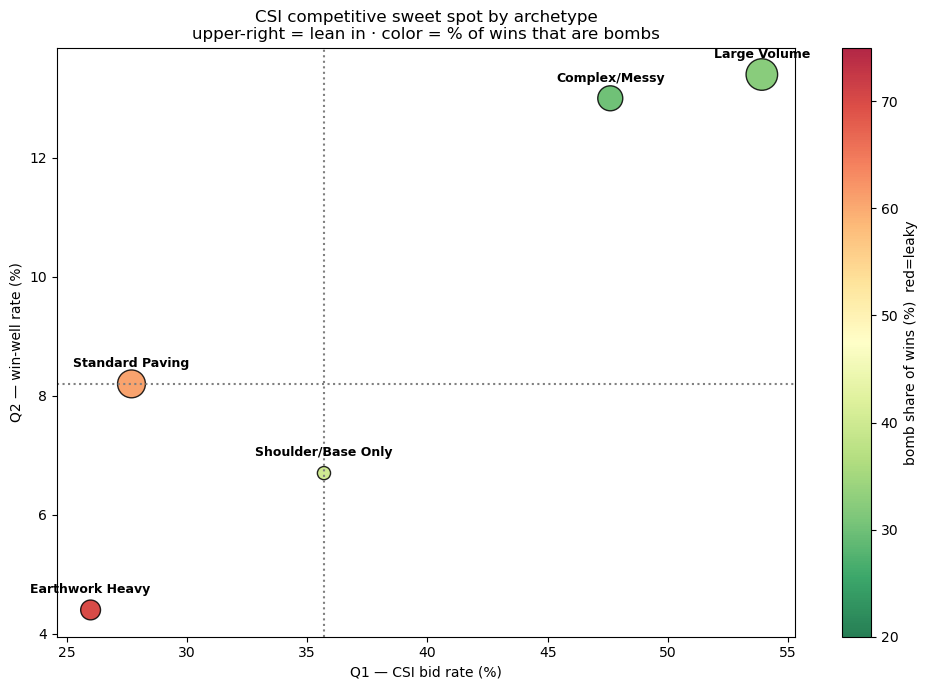

In [3]:
plot = s[s["archetype"]!="Unknown/NoQty"].copy()
fig, ax = plt.subplots(figsize=(10,7))
sc = ax.scatter(plot["bid_rate"], plot["win_well_rate"], s=plot["n_bid"]*3,
                c=plot["bomb_share_of_wins"], cmap="RdYlGn_r", vmin=20, vmax=75, alpha=.85, edgecolor="k")
for _,r in plot.iterrows(): ax.annotate(r["archetype"],(r.bid_rate,r.win_well_rate),fontsize=9,fontweight="bold",ha="center",xytext=(0,12),textcoords="offset points")
ax.axvline(plot["bid_rate"].median(), ls=":", c="gray"); ax.axhline(plot["win_well_rate"].median(), ls=":", c="gray")
ax.set_xlabel("Q1 — CSI bid rate (%)"); ax.set_ylabel("Q2 — win-well rate (%)")
ax.set_title("CSI competitive sweet spot by archetype\nupper-right = lean in · color = % of wins that are bombs")
fig.colorbar(sc, label="bomb share of wins (%)  red=leaky"); plt.tight_layout(); plt.show()

In [4]:
p = s[s["archetype"]!="Unknown/NoQty"]
print("Corr(bid_rate, win_well_rate) =", round(p["bid_rate"].corr(p["win_well_rate"]),2),
      "-> high & positive: CSI already bids where it wins well")

Corr(bid_rate, win_well_rate) = 0.91 -> high & positive: CSI already bids where it wins well


## Conclusions
1. **Sweet spot = Large Volume + Complex/Messy** (bid often, win well, low bomb).
2. **Selection is well-calibrated** — bid-rate vs win-well-rate correlate **0.91**.
3. **The leak is pricing, not selection** — 60-70% of CSI's wins in **Standard
   Paving** and **Earthwork Heavy** are bombs. Fix price discipline there.

See `2026-06-04_sweetspot_findings.md` for the written narrative and
`2026-06-04_00_METHODOLOGY.md` for the full rationale.